# Проект. Исследование стартапов

## Введение

### Цели и задачи проекта 

Цель: Выявить ключевые характеристики финансирования стартапов (по отраслям, типам раундов и объемам), которые сопутствуют успешному возврату инвестиций, для формирования рекомендаций по стратегии покупки стартапов на 2015 год.

Задачи:
- Подготовка данных: очистка от пропусков, дубликатов и выбросов;
- Выделить группы компаний по срокам финансирования и сравнить их по количеству и объёму инвестиций;
- Классифицировать сегменты рынка на массовые, средние и нишевые;
- Определить типичные и аномальные значения объёмов финансирования, исключить выбросы и ограничить период исследования;
- Сравнить популярность и объёмы разных типов финансирования;
- Проанализировать динамику раундов и объёмов инвестиций по годам, а также изменения в массовых сегментах рынка;
- Рассчитать долю возврата средств для разных типов финансирования и оценить её устойчивость;
- Подвести итоговые выводы и дать рекомендации, куда и каким образом было бы целесообразно инвестировать

### Структура проекта

1. Цели и задачи проекта
2. Знакомство с данными: загрузка и предобработка
3. Инжиниринг признаков
4. Работа с выбросами и анализ
5. Анализ динамики
6. Итоговый вывод и рекомендации

## Знакомство с данными: загрузка и предобработка

### Описание данных

Таблица `cb_investments` cодержит информацию о компаниях и состоявшемся финансировании:

* `name` — название компании.
* `homepage_url` — ссылка на сайт компании.
* `category_list` — категории, в которых работает компания. Указываются через `|`.
* `market` — основной рынок или отрасль компании.
* `funding_total_usd` — общий объём привлечённых инвестиций в долларах США.
* `status` — текущий статус компании, например `operating`, `closed` и так далее.
* `country_code` — код страны, например USA.
* `state_code` — код штата или региона, например, CA.
* `region` — регион, например, SF Bay Area.
* `city` — город, в котором расположена компания.
* `funding_rounds` — общее число раундов финансирования.
* `participants` — число участников в раундах финансирования.
* `founded_at` — дата основания компании.
* `founded_month` — месяц основания в формате `YYYY-MM`.
* `founded_quarter` — квартал основания в формате `YYYY-QN`.
* `founded_year` — год основания.
* `first_funding_at` — дата первого финансирования.
* `mid_funding_at` — дата среднего по времени раунда финансирования.
* `last_funding_at` — дата последнего финансирования.
* `seed` — сумма инвестиций на посевной стадии.
* `venture` — сумма венчурных инвестиций.
* `equity_crowdfunding` — сумма, привлечённая через долевой краудфандинг.
* `undisclosed` — сумма финансирования нераскрытого типа.
* `convertible_note` — сумма инвестиций через конвертируемые займы.
* `debt_financing` — сумма долгового финансирования.
* `angel` — сумма инвестиций от бизнес-ангелов.
* `grant` — сумма полученных грантов.
* `private_equity` — сумма инвестиций в виде прямых (частных) вложений.
* `post_ipo_equity` — сумма финансирования после IPO.
* `post_ipo_debt` — сумма долгового финансирования после IPO.
* `secondary_market` — сумма сделок на вторичном рынке.
* `product_crowdfunding` — сумма, привлечённая через продуктовый краудфандинг.
* `round_A` — `round_H` — сумма инвестиций в соответствующем раунде.

Таблица `cb_returns` Содержит информацию об объёмах возвратов по годам и типам финансирования в миллионах долларов:


* `year` — год возврата средств.
* `seed` — сумма возвратов от посевных инвестиций.
* `venture` — сумма возвратов от венчурных инвестиций.
* `equity_crowdfunding` — сумма, возвращённая по долевому краудфандингу.
* `undisclosed` — сумма возвратов нераскрытого типа.
* `convertible_note` — сумма возвратов через конвертируемые займы.
* `debt_financing` — сумма возвратов от долгового финансирования.
* `angel` — сумма возвратов бизнес-ангелам.
* `grant` — сумма возвратов по грантам.
* `private_equity` — сумма возвратов прямых (частных) вложений.
* `post_ipo_equity` — сумма возвратов от IPO.
* `post_ipo_debt` — сумма возвратов от долгового IPO.
* `secondary_market` — сумма возвратов от сделок на вторичном рынке.
* `product_crowdfunding` — сумма возвратов по продуктовому краудфандингу.



### Вывод общей информации


Начнём с загрузки библиотек и датасетов  `cb_investments` и `cb_returns`. Будем использовать pandas и библиотеки визуализации данных matplotlib. Данные датасетов сохраним в двух переменных: `invest_df` и `return_df`.

In [1]:
# Импортируем библиотеки
import pandas as pd

# Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt


In [2]:
def show_missing_stats(tmp0):
    """
    Функция для отображения статистики пропущенных значений в DataFrame.
    """
    missing_stats = pd.DataFrame({
        'Кол-во пропусков': tmp0.isnull().sum(),
        'Доля пропусков': tmp0.isnull().mean()
    })
    missing_stats = missing_stats[missing_stats['Кол-во пропусков'] > 0]
    
    if missing_stats.empty:
        return "Пропусков в данных нет"
    
    # Форматируем при выводе через Styler
    return (missing_stats.style.format({'Доля пропусков': '{:.4f}'}).background_gradient(cmap='Blues'))

In [3]:
# Выгрузим данные в переменную invest_df и выведем первые строки датафрейма 
invest_df = pd.read_csv("data/investments.csv", sep=';', low_memory=False)
invest_df.head().T

,0,1,2,3,4
name,Harvard University,University of New Brunswick,DuPont,University of Michigan,Case Western Reserve University
homepage_url,http://harvard.edu,http://www.unb.ca,http://www.dupont.com,http://www.umich.edu/,http://www.case.edu
category_list,|Education|,NaN,|Business Services|Agriculture|Automotive|Inve...,|Education|,|Education|
market,Education,NaN,Business Services,Education,Education
funding_total_usd,"9,00,00,000","20,00,000","90,00,000","77,00,000","5,40,000"
status,operating,operating,operating,operating,operating
country_code,USA,NaN,USA,USA,USA
state_code,MA,NaN,DE,MI,OH
region,Boston,NaN,"Wilmington, Delaware",Detroit,Cleveland
city,Cambridge,NaN,Wilmington,Ann Arbor,Cleveland


In [4]:
# Выводим информацию о датафрейме 
invest_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3    market               45477 non-null  object 
 4    funding_total_usd    49438 non-null  object 
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15  founded_year       

In [5]:
# Проверим количество пропусков в invest_df
show_missing_stats(invest_df)

,Кол-во пропусков,Доля пропусков
name,4857,0.0895
homepage_url,8305,0.1530
category_list,8817,0.1624
market,8817,0.1624
funding_total_usd,4856,0.0894
status,6170,0.1136
country_code,10129,0.1866
state_code,24133,0.4445
region,10129,0.1866
city,10972,0.2021


Датасет `invest_df` включает 54294 строки и 40 столбцов, занимая 16.6 МБ. Типы данных распределены следующим образом: 24 числовых (float64) и 16 строковых (object).

Проверка типов показала:

Строковые (`object`) корректны для текстовых полей (`name, homepage_url, category_list, region, city`, `founded_quarter`, `founded_month`, `market`).

Категориальные признаки (`status, country_code, state_code`) необходимо перевести в тип `category` для оптимизации памяти, так как количество уникальных значений в них ограничено.

Метрики (`funding_rounds, participants`,  `founded_year`, `funding_total_usd`) требуют приведения к целочисленному (int)

Временные метки (столбцы с суффиксом `_at`) будут преобразованы в формат `datetime`.

Остальные 24 числовых столбца типа float оставляем без изменений (возможна лишь незначительная оптимизация размерности).

Краткий анализ пропусков:

Минимальный уровень пропусков (~8.94%) — у 24 колонок (все финансовые суммы + funding_total_usd, funding_rounds, first_funding_at, last_funding_at).
Вероятная причина: для компаний без финансирования эти поля пустые. 

Максимальный уровень пропусков (44.25%) — у колонок participants (число участников раунда) и mid_funding_at (дата промежуточного раунда).
Вероятная причина: эти данные собираются не для всех компаний

Теперь познакомимся с данными датасета `return_df`

In [84]:
# Выгружаем данные в переменную return_df и выведем первые строки датафрейма 
return_df = pd.read_csv("data/returns.csv",
    index_col='year' # Задаем столбец, который станет индексом
)
return_df.head()

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2000,16.70,55.40,0.0,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.0,0.20,0.0
2001,2.88,23.49,0.0,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.0,0.46,0.0
2002,6.59,209.42,0.0,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.0,0.06,0.0
2003,7.74,233.86,0.0,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.0,0.08,0.0
2004,9.93,555.90,0.0,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.0,0.55,0.0


In [85]:
# Выводим информацию о датафрейме 
return_df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 15 entries, 2000 to 2014
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   seed                  15 non-null     float64
 1   venture               15 non-null     float64
 2   equity_crowdfunding   15 non-null     float64
 3   undisclosed           15 non-null     float64
 4   convertible_note      15 non-null     float64
 5   debt_financing        15 non-null     float64
 6   angel                 15 non-null     float64
 7   grant                 15 non-null     float64
 8   private_equity        15 non-null     float64
 9   post_ipo_equity       15 non-null     float64
 10  post_ipo_debt         15 non-null     float64
 11  secondary_market      15 non-null     float64
 12  product_crowdfunding  15 non-null     float64
dtypes: float64(13)
memory usage: 1.6 KB


Датасет `return_df` включает 15 строк и 13 столбцов, объем занимаемой памяти - 1.6 KB. Все столбцы числового типа данных, в данных нет пропусков. Ввиду крайне малого объема данных оптимизация типов памяти нецелесообразна, все столбцы оставляем в текущем формате.

###  Предобработка данных

В процессе предобработки проверим уникальные значения категориальных столбцов, числовые приведем к нужному типу с понижением разрядности, обработаем дубликаты и пропуски, где это необходимо.

In [8]:
# Сохраним количество строк перед предобработкой
row_count = len(invest_df)
row_count

54294

In [9]:
# Удалим лишние пробелы в названиях колонок
invest_df.columns = invest_df.columns.str.strip()
return_df.columns = return_df.columns.str.strip()

In [10]:
# Удалим выделение разрядов и пробелы в столбце `funding_total_usd`
invest_df['funding_total_usd'] =invest_df['funding_total_usd'].str.replace(',', '').str.replace(' ', '')

In [11]:
# Приведем его к числовому типу.
invest_df['funding_total_usd'] = pd.to_numeric(invest_df['funding_total_usd'], errors='coerce').astype('Int64')

Обработаем типы данных в столбцах, которые хранят значения даты и времени

In [12]:
# Приведем колонку founded_year к целому числу.
invest_df['founded_year'] = pd.to_numeric(invest_df['founded_year'], errors='coerce').astype('Int64')

In [13]:
# Список колонок для преобазования в datetime
col = ['founded_at', 'first_funding_at', 'mid_funding_at', 'last_funding_at']

# Преобразуем тип данных
invest_df[col] = invest_df[col].apply(pd.to_datetime, errors='coerce')


Обработаем столбцы, которые содержат категориальные данные.

In [75]:
# Посмотрим на значения в колонке `market`
invest_df.market.unique().tolist()[:10]

['education',
 nan,
 'business services',
 'social media',
 'hardware + software',
 'biotechnology',
 'utilities',
 'hospitality',
 'enterprise software',
 'manufacturing']

In [76]:
# Уберем пробелы и приведем в нижний регистр
invest_df['market'] = invest_df['market'].str.strip().str.lower()
invest_df.market.unique().tolist()[:10]

['education',
 nan,
 'business services',
 'social media',
 'hardware + software',
 'biotechnology',
 'utilities',
 'hospitality',
 'enterprise software',
 'manufacturing']

In [80]:
# Выведем уникальные значения остальных категориальных колонок
for col in invest_df[['status', 'country_code', 'state_code']]:
    display(f"Колонка: {col}")
    display(invest_df[col].unique().tolist()[:15])
    

'Колонка: status'

['operating', 'acquired', nan, 'closed']

'Колонка: country_code'

['USA',
 nan,
 'DEU',
 'JPN',
 'CAN',
 'IND',
 'CHE',
 'PHL',
 'ISR',
 'ITA',
 'GBR',
 'ESP',
 'DNK',
 'BEL',
 'MEX']

'Колонка: state_code'

['MA',
 nan,
 'DE',
 'MI',
 'OH',
 'LA',
 'NC',
 'VA',
 'CA',
 'NY',
 'FL',
 'MD',
 'MO',
 'NJ',
 'OR']

In [18]:
# Преобразуем тип данных для категориальных признаков
col = ['status', 'country_code', 'state_code']
invest_df[col] = invest_df[col].astype('category')

In [19]:
# Приведем тип данных колонок 'funding_rounds' и  'participants' к целочисленному
col_1 = ['funding_rounds', 'participants']
invest_df[col_1] = invest_df[col_1].astype('Int64')

In [20]:
# Список всех финансовых колонок
float_cols = [
    'seed', 'venture', 'equity_crowdfunding', 'undisclosed', 
    'convertible_note', 'debt_financing', 'angel', 'grant', 
    'private_equity', 'post_ipo_equity', 'post_ipo_debt', 
    'secondary_market', 'product_crowdfunding',
    'round_A', 'round_B', 'round_C', 'round_D', 
    'round_E', 'round_F', 'round_G', 'round_H'
]

# Снижаем размерность до float32
invest_df[float_cols] = invest_df[float_cols].astype('float32')

In [21]:
# Проверим тип всех колонок после преобразований
invest_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   name                  49437 non-null  object        
 1   homepage_url          45989 non-null  object        
 2   category_list         45477 non-null  object        
 3   market                45477 non-null  object        
 4   funding_total_usd     40907 non-null  Int64         
 5   status                48124 non-null  category      
 6   country_code          44165 non-null  category      
 7   state_code            30161 non-null  category      
 8   region                44165 non-null  object        
 9   city                  43322 non-null  object        
 10  funding_rounds        49438 non-null  Int64         
 11  participants          30473 non-null  Int64         
 12  founded_at            38553 non-null  datetime64[ns]
 13  founded_month   

Обработаем полные дубликаты в данных и пропуски в `funding_total_usd`. Удалим строки, которые не несут какой-либо информации и не содержат данных о финансировании.

In [22]:
# Посмотрим на пропуски в колонке `name`
invest_df[invest_df['name'].isna()]

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
27212,NaN,http://tellitin10.com,|Startups|,startups,25000,closed,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
49438,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49439,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49440,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49441,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
54289,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54290,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54291,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54292,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [23]:
# Удалим строки с пропусками в колонке `name`, где не было финансирования
invest_df_0 = invest_df[~(invest_df['name'].isna() & invest_df['funding_total_usd'].isna())]

In [24]:
# Проверяем полные дубликаты в датафрейме 
invest_df_0.duplicated().sum()

0

In [25]:
# Посмотрим на пропуски в колонке `funding_total_usd`
invest_df_0[invest_df_0['funding_total_usd'].isna()]

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
13,University of Rochester,http://www.rochester.edu,NaN,NaN,<NA>,operating,USA,NY,"Rochester, New York",Rochester,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
15,FKK Corporation,http://www.fkk-corporation.com,|Hardware + Software|,hardware + software,<NA>,operating,JPN,NaN,Kyoto,Kyoto-shi,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
19,Laclede Group,http://www.thelacledegroup.com,|Utilities|,utilities,<NA>,operating,USA,MO,St. Louis,St Louis,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
27,Bayer AG,http://bayer.com,|Pharmaceuticals|Biotechnology|,pharmaceuticals,<NA>,acquired,DEU,NaN,Leverkusen,Leverkusen,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
35,Asia Pacific Marine Container Lines,http://AsiaPacificMarine.com,|Logistics Company|Shipping Broker Industry|Sh...,shipping,<NA>,operating,CAN,BC,Vancouver,Vancouver,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49419,Pollask,http://www.pollask.com,NaN,NaN,<NA>,operating,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
49421,Studying.to,http://www.studying.to,|College Recruiting|Internet Marketing|Educati...,education,<NA>,operating,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
49425,Orori,http://orori.com,NaN,NaN,<NA>,operating,IDN,NaN,Jakarta,Jakarta,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
49426,Virometix AG,http://virometix.com,NaN,NaN,<NA>,operating,CHE,NaN,Schlieren,Schlieren,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [26]:
# Удалим строки с пропусками в колонке `funding_total_usd`
df = invest_df_0.dropna(subset=['funding_total_usd']).copy()

In [27]:
# Итоговый датафрейм после предобработки
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 40907 entries, 0 to 49437
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   name                  40906 non-null  object        
 1   homepage_url          38593 non-null  object        
 2   category_list         38404 non-null  object        
 3   market                38404 non-null  object        
 4   funding_total_usd     40907 non-null  Int64         
 5   status                39802 non-null  category      
 6   country_code          37088 non-null  category      
 7   state_code            25619 non-null  category      
 8   region                37088 non-null  object        
 9   city                  36402 non-null  object        
 10  funding_rounds        40907 non-null  Int64         
 11  participants          27331 non-null  Int64         
 12  founded_at            32200 non-null  datetime64[ns]
 13  founded_month   

Заполним пропуски в значениях `mid_funding_at` на основании значений в столбцах `first_funding_at` и `last_funding_at`. В качестве нового значения вместо пропусков возьмем приблизительно середину интервала между этими двумя датами.

In [28]:
# Вычисляем разницу в днях между датами и делим на 2 (получаем число дней)
period_days = (df['last_funding_at'] - df['first_funding_at']).dt.days // 2

# Прибавляем это количество дней к первой дате
mid_date = df['first_funding_at'] + pd.to_timedelta(period_days, unit='D')

# Заполняем пропуски
df['mid_funding_at'] = df['mid_funding_at'].fillna(mid_date)

Проверим количество пропусков после преодбработки

In [29]:
show_missing_stats(df)

,Кол-во пропусков,Доля пропусков
name,1,0.0000
homepage_url,2314,0.0566
category_list,2503,0.0612
market,2503,0.0612
status,1105,0.0270
country_code,3819,0.0934
state_code,15288,0.3737
region,3819,0.0934
city,4505,0.1101
participants,13576,0.3319


In [30]:
# Выводим результаты после предобработки

print(f"Количество строк до предобработки данных: {row_count}")
print(f"Количество строк после предобработки данных: {len(df)}")
print(f"Количество удаленных строк после предобработки в абсолютном значении: " \
      f"{row_count - len(df)}")
print(f"Процент потерь: " \
      f"{round((row_count - len(df))/row_count, 4)*100}")

Количество строк до предобработки данных: 54294
Количество строк после предобработки данных: 40907
Количество удаленных строк после предобработки в абсолютном значении: 13387
Процент потерь: 24.66


### Промежуточный вывод

1. Общая информация о данных
- Размер исходного датасета invest_df - 54294 строк и 40 столбцов
- Размер после всех преобразований -  40907 строки и 40 столбцов
- Данные содержат информацию о компаниях и состоявшемся финансировании:.

2. Типы данных
- Были выполнены преобразования: понижена разрядность для числовых данных, категориальные данные были приведены к типу `category`
- После преобразования все колонки имеют корректные типы данных

3. Пропуски
- Количество пропусков до обработки.
В данных присутствуют 333208 пропусков. 
Распределение по колонкам:
    
| Название колонки | Кол-во пропусков | Доля пропусков (%) |
| :--- | :--- | :--- |
| state_code | 24133 | 44.45% |
| mid_funding_at | 24006 | 44.21% |
| participants | 23821 | 43.87% |
| city | 10972 | 20.21% |
| country_code | 10129 | 18.66% |
| region | 10129 | 18.66% |
| category_list | 8817 | 16.24% |
| market | 8817 | 16.24% |
| homepage_url | 8305 | 15.30% |
| founded_month | 15812 | 29.12% |
| founded_quarter | 15812 | 29.12% |
| founded_at | 15741 | 28.99% |
| founded_year | 15740 | 28.99% |
| funding_total_usd | 13387 | 24.66% |
| status | 6170 | 11.36% |
| first_funding_at | 4866 | 8.96% |
| last_funding_at | 4862 | 8.95% |
| name | 4857 | 8.95% |
| funding_rounds | 4856 | 8.94% |
| seed | 4856 | 8.94% |
| venture | 4856 | 8.94% |
| equity_crowdfunding | 4856 | 8.94% |
| undisclosed | 4856 | 8.94% |
| convertible_note | 4856 | 8.94% |
| debt_financing | 4856 | 8.94% |
| angel | 4856 | 8.94% |
| grant | 4856 | 8.94% |
| private_equity | 4856 | 8.94% |
| post_ipo_equity | 4856 | 8.94% |
| post_ipo_debt | 4856 | 8.94% |
| secondary_market | 4856 | 8.94% |
| product_crowdfunding | 4856 | 8.94% |
| round_A | 4856 | 8.94% |
| round_B | 4856 | 8.94% |
| round_C | 4856 | 8.94% |
| round_D | 4856 | 8.94% |
| round_E | 4856 | 8.94% |
| round_F | 4856 | 8.94% |
| round_G | 4856 | 8.94% |
| round_H | 4856 | 8.94% |

В процессе преобработки  пропуски в значениях `mid_funding_at`  были заполнены серединой интервала между `first_funding_at` и `last_funding_at`. Так же были удалены строки, которые не содержат данных о финансировании и не имеют названий компании.

4. Дубликаты
- Количество явных дубликатов (полных) - 0
- Количество неявных дубликатов (по ключевым полям) - 0
- Количество строк после обработки 40907

5. В датасете cb_returns 15 строк и 14 столбцов.
Количество пропусков - 0.

В процессе преобработки столбец `year` сделали индексом всего датасета
    
6. Итоговое состояние данных
- Количество строк после всех преобразований в основном датасете df - 40907
- Процент потерь: 24.66

На этом предобработка завершена, данных достаточно для дальнейшего анализа. Предоставленные данные адекватного качества и требуют не так много действий по предобработке


##  Инжиниринг признаков

###  Группы по срокам финансирования

Разделим все компании на три группы:

* Единичное финансирование — был всего один раунд финансирования.

* Срок финансирования до года — между первым и последним раундом финансирования прошло не более года.

* Срок финансирования более года.


In [31]:
# Создаём пустую колонку 
df['funding_type'] = 'более года'  # Значение по умолчанию

#  Единичное финансирование
df.loc[df['funding_rounds'] == 1, 'funding_type'] = 'единичное'

# Менее года (исключая единичное)
mask_less_year = (
    (df['funding_rounds'] > 1) & 
    ((df['last_funding_at'] - df['first_funding_at']).dt.days < 365)
)
df.loc[mask_less_year, 'funding_type'] = 'менее года'

In [32]:
# Посчитаем количество компаний по категориям финансирования
df['funding_type'].value_counts()

единичное     24113
более года    12387
менее года     4407
Name: funding_type, dtype: int64

Визуализируем соотношение этих групп, создав графики по количеству компаний и объему финансирования:

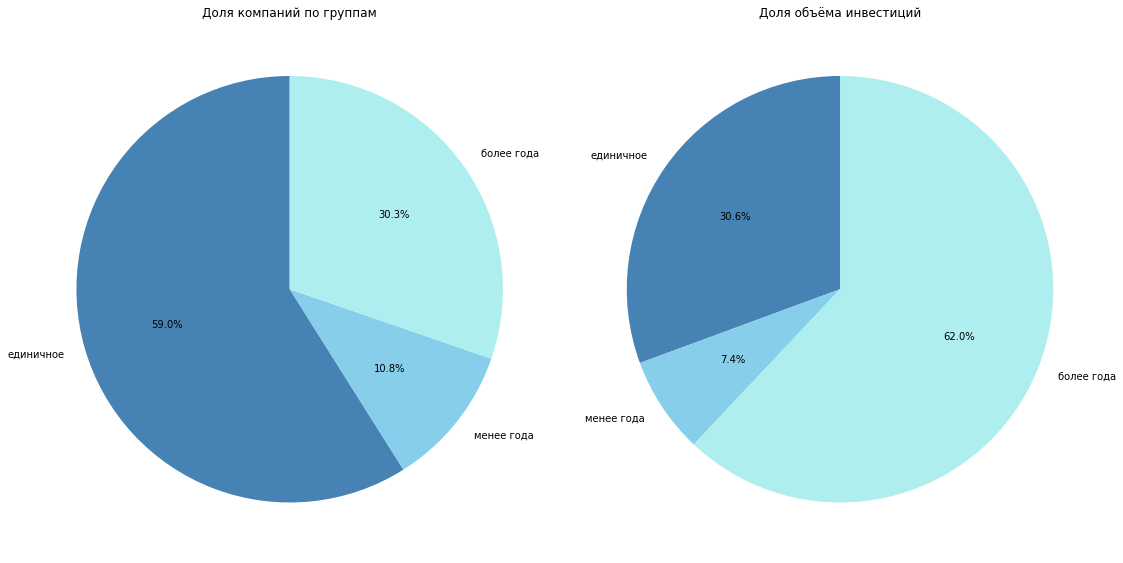

In [83]:
# Создадим список используемых цветов
color_list = ['steelblue', 'skyblue', 'paleturquoise']

# Создадим список категорий
type_order = ['единичное','менее года', 'более года']

# Строим круговую диаграмму
grouped_data = round(df['funding_type'].value_counts(normalize=True)*100, 2)
grouped_data_1 = df.groupby('funding_type')['funding_total_usd'].sum()/df['funding_total_usd'].sum()

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

grouped_data.reindex(type_order).plot(
    kind='pie', colors=color_list, autopct='%1.1f%%',
    ax=axes[0], startangle=90
)
axes[0].set_title('Доля компаний по группам')
axes[0].set_ylabel('')

(grouped_data_1 * 100).reindex(type_order).plot(
    kind='pie', colors=color_list, autopct='%1.1f%%',
    ax=axes[1], startangle=90
)
axes[1].set_title('Доля объёма инвестиций')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

Более половины компаний (59%) получили единичное финансирование. Это говорит о том, что либо проекты очень быстро выходят на самоокупаемость, либо (что чаще всего) — большинство стартапов закрываются после первой неудачной попытки масштабирования. Всего 10.8% компаний смогли привлечь несколько раундов финансирования в течение одного года. Такие компании показывают сверхбыстрый рост и успевают закрыть несколько сделок за 12 месяцев. Это, как правило, проекты из популярных сейчас сфер (например, AI). Долгосрочные проекты с финансированием более года составляют треть (30%).

Наибольший объем инвестиций (62%) приходится на долгосрочные стартапы с периодом финансирования более года. Как правило, это могут быть высокотехнологичные стартапы или компании, реализующие стратегию поэтапного масштабирования (например, выход на новые географические рынки). Наименьший процент так же занимают компании с финансированием менее года. При этом интересно, что компании с единичным раундом, составляющие большинство по численности (59%), привлекают лишь 30,6% от общего объема средств. Это подтверждает гипотезу о том, что массовый сегмент стартапов состоит из "точечных" проектов с небольшим бюджетом.

### Выделение средних и нишевых сегментов рынка

Выделим среди всех сегментов рынка нишевые и средние. Сегменты, к которым относится более 120 компаний, будут относиться к массовым, сегменты, в которые входит от 35 до 120 включительно, -  к средним, а сегменты до 35 компаний отнесем к нишевым. Рассчитаем, сколько сегментов попадает в каждую из категорий и построим график распределения количества компаний в сегментах. 

In [35]:
# Рассчитаем количество компаний в каждом сегменте
segment_counts = df['market'].value_counts()

# Обозначим верхнюю границу для категоризации
upper_bound = segment_counts.max() + 1


In [36]:
# Выделим нужные категории 'Нишевые', 'Средние', 'Массовые'
market_type = pd.cut(
    segment_counts,
    bins=[-1, 35, 121, upper_bound],
    labels=['Нишевые', 'Средние', 'Массовые']
)


In [37]:
# Найдем долю компаний в каждой категории
category_counts = market_type.value_counts(normalize=True)
category_counts


Нишевые     0.733503
Средние     0.144670
Массовые    0.121827
Name: market, dtype: float64

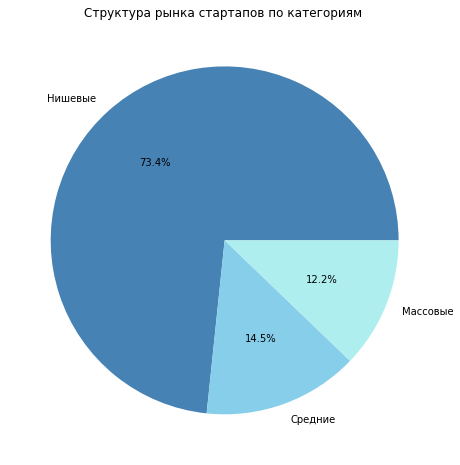

In [38]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(12, 8))

# Строим круговую диаграмму
ax = category_counts.plot(kind = 'pie',
                                  colors = color_list,
                                  autopct='%1.1f%%')

# Настраиваем оформление графика
plt.title('Структура рынка стартапов по категориям ')
plt.ylabel('')
plt.show()

Построим график распределния количества компаний в сегментах и выделим границы между категориями

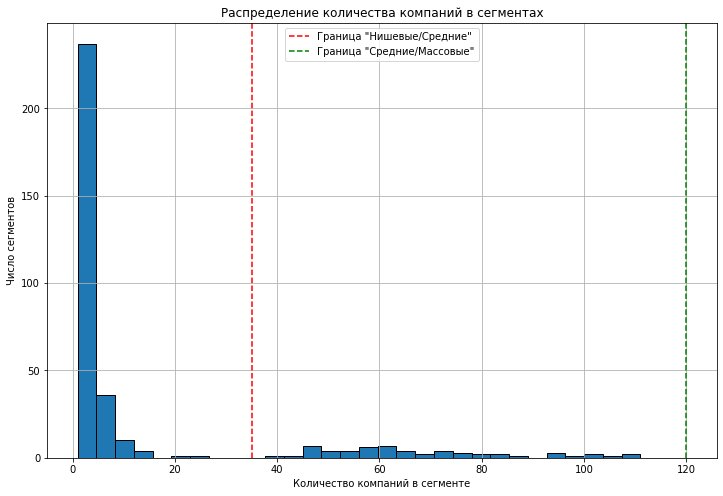

In [39]:
# Построим гистограмму
segment_counts[segment_counts<=120].hist(figsize=(12, 8), bins=30, edgecolor='black')

# Создадим границы между категориями сегментов
plt.axvline(x=35, color='red', linestyle='--', label='Граница "Нишевые/Средние"')
plt.axvline(x=120, color='green', linestyle='--', label='Граница "Средние/Массовые"')

# Настраиваем оформление графика
plt.xlabel('Количество компаний в сегменте')
plt.ylabel('Число сегментов')
plt.title('Распределение количества компаний в сегментах')
plt.legend()
plt.grid
plt.show()


Оставим в столбце `market` только массовые сегменты. Для остальных сегментов заменим значения на заглушки — `niche` для нишевых и `mid` для средних.

In [40]:
# Нишевые сегменты (< 35 компаний)
df.loc[df.market.isin(segment_counts.index[segment_counts < 35]), 'market'] = 'niche'

# Средние сегменты (от 35 до 120 компаний)
df.loc[df.market.isin(segment_counts.index[(segment_counts >= 35) & (segment_counts <= 120)]), 'market'] = 'mid'


На основании категоризации, можно сделать вывод, что подавляющее большинство сегментов (73,4%) являются нишевыми и насчитывают менее 35 компаний. Массовых, широко представленных сегментов (более 120 компаний) — абсолютное меньшинство, всего 12,2%. Это говорит о том, что большинство стартапов стараются занять уникальные ниши, чтобы избежать прямой конкуренции с компаниями-гигантами. С точки зрения инвестиций стоит присмотреться именно к средним сегментам: такие компании более выживаемые на рынке в сравнении с нишевыми, но в них еще нет перенасыщения и сильной конкуренции, как в массовых сегментах.

##  Работа с выбросами и анализ

###  Анализируем и помечаем выбросы в каждом из сегментов

По предобработанному столбцу `funding_total_usd` графическим образом оценим, какой размер общего финансирования для одной компании будет типичным, а какой — выбивающимся. 

In [41]:
# Посмотрим статистику по столбцу funding_total_usd и приведем к млн $
stats = (df['funding_total_usd'] / 1000000).describe()
stats

count    40907.000000
mean        15.912526
std        168.678800
min          0.000001
25%          0.350000
50%          2.000000
75%         10.000000
max      30079.503000
Name: funding_total_usd, dtype: float64

Для наглядности диаграмма размаха построена без отображения выбросов, так как максимальное значение финансирования (30 млрд) значительно превышает медиану (2 млн) и искажает визуальное восприятие.

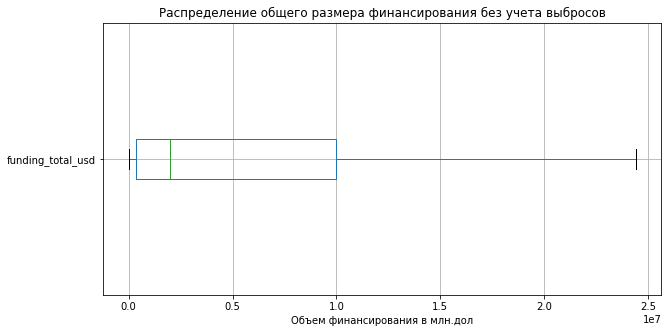

In [42]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(10, 5))

# Строим диаграмму размаха значений в столбце funding_total_usd
df.boxplot(column='funding_total_usd', vert=False, showfliers=False)

# Добавляем заголовок и метки оси
plt.title('Распределение общего размера финансирования без учета выбросов')
plt.xlabel('Объем финансирования в млн.дол')

# Выводим график
plt.show()

In [43]:
# Рассчитаем квартили Q1 и Q3
Q1 = stats.quantile(0.25)
Q3 = stats.quantile(0.75)

# Рассчитаем межквартильный размах IQR как разницу между Q3 и Q1
IQR = Q3 - Q1

# Границы типичных значений (без выбросов)
# Рассчитаем нижний порог, как минимальное значение, т.к. финансирование не может быть отрицательным
lower_bound_df = stats.min()

# Рассчитаем верхний порог
upper_bound_df = Q3 + 1.5 * IQR

# Выведем общую информацию
print(f"Q1 (25-й перцентиль): {Q1:.2f} млн $")
print(f"Медиана: {stats.quantile(0.5):.2f} млн $")
print(f"Q3 (75-й перцентиль): {Q3:.2f} млн $")
print(f"\nТипичный интервал (без выбросов):")
print(f"[{lower_bound_df:.2f} млн $; {upper_bound_df:.2f} млн $]")

Q1 (25-й перцентиль): 1.59 млн $
Медиана: 12.96 млн $
Q3 (75-й перцентиль): 7646.38 млн $

Типичный интервал (без выбросов):
[0.00 млн $; 19113.58 млн $]


Определеним компании с аномальным объёмом общего финансирования, используя метод IQR, отдельно по каждому сегменту. 

In [44]:
# Найдем уникальные значения в столбце 'markets'
markets = df.market.unique()

# Создадим столбец 'anomaly' , который по умолчанию будет содержать значение False
df['anomaly'] = False

for market_type in markets:
    # Выбираем данные по текущему сегменту
    segment_data = df[df['market'] == market_type]['funding_total_usd'] 
    
    # Рассчитываем квартили
    Q1 = segment_data.quantile(0.25)
    Q3 = segment_data.quantile(0.75)
    IQR = Q3 - Q1
    
    # Верхняя граница нормального диапазона
    upper_bound = Q3 + 1.5 * IQR
    
    # Отмечаем аномалии: значения за пределами верхней границы
    df.loc[
        (df['market'] == market_type) & 
        (df['funding_total_usd']  > upper_bound), 'anomaly'
    ] = True


Выделим сегменты рынка с наибольшей долей компаний, получивших аномальное финансирование, и выведем топ-5 таких сегментов.

In [45]:
top_segments = df.groupby('market').anomaly.mean().sort_values(ascending = False).head(5)*100
top_segments 

market
real estate        17.204301
entertainment      16.666667
consulting         16.618911
search             16.494845
cloud computing    16.447368
Name: anomaly, dtype: float64

Анализ квартилей показывает крайнюю асимметрию рынка: при медиане в 12.96 млн долларов, третий квартиль достигает 7.6 млрд, что свидетельствует о концентрации основных инвестиций в узком круге проектов. Типичный интервал финансирования (без выбросов) простирается от 0 до 19.1 млрд долларов. Среди сегментов наиболее подвержены аномально крупным сделкам  Real Estate и Entertainment, Consulting, Search и Cloud Computing. Стоит учитывать, что входной порог в эти ниши очень высокий. При прогнозировании финансирования стоит использовать медиану (12.96 млн), а не среднее значение, так как среднее будет сильно завышено из-за 30-миллиардных сделок.

### Определяем границы рассматриваемого периода, отбрасываем аномалии

Проверим по датасету, можно ли считать, что нам предоставлены полные данные за 2014 год. 

In [46]:
# Выведем минимальный месяц из даты первого финансирования
df[df['first_funding_at'].dt.year ==2014].last_funding_at.dt.month.min()

1

In [47]:
# Выведем максимальный месяц из даты последнего финансирования
df[df['last_funding_at'].dt.year ==2014].last_funding_at.dt.month.max()

12

Так как последний месяц последнего финансирования за 2014 год - декабрь, а первый месяц - январь, можно сделать вывод, что за 2014 год предоставлены полные данные.

Исключим из датасета компании, которые ранее посчитали получившими аномальное финансирование.

In [48]:
# Удаляем компании с аномальным финансированием
df_1 = df[df['anomaly'] == False].copy()

Исключим из датасета годы, в которых было зафиксировано менее 50 раундов финансирования.

In [49]:
# Создадим маску для отбора годов, в которых было зафиксировано 50 и более раундов финансирования.
mask = df_1.groupby(df_1['mid_funding_at'].dt.year).funding_rounds.sum() >= 50

# Выведем список годов, соответствующих условию
year_list = mask[mask == True].index.tolist()
year_list

[2000.0,
 2001.0,
 2002.0,
 2003.0,
 2004.0,
 2005.0,
 2006.0,
 2007.0,
 2008.0,
 2009.0,
 2010.0,
 2011.0,
 2012.0,
 2013.0,
 2014.0]

In [50]:
# Исключим из датасета годы, в которых было зафиксировано менее 50 раундов финансирования.
df_2 = df_1[df_1['mid_funding_at'].dt.year.isin(year_list)].copy()

In [51]:
df_2.groupby(df_2['mid_funding_at'].dt.year)['funding_rounds'].sum()

mid_funding_at
2000      122
2001       84
2002      107
2003      128
2004      189
2005      958
2006     1881
2007     2849
2008     3686
2009     4669
2010     6199
2011     7617
2012     9753
2013    12945
2014     7244
Name: funding_rounds, dtype: Int64

Так как нас интересует обычный для рассматриваемого периода размер средств, который предоставлялся компаниям, из датасета были исключены компании, которые получили аномальное финансирование. Также в итоговый датафрейм `df_2` вошли только те годы, в которые было зафиксировано 50 и более раундов финансирования.

###  Анализ типов финансирования по объёму и популярности

Ориентируясь на значения в столбцах `seed`, `venture`, `equity_crowdfunding`, `undisclosed`, `convertible_note`, `debt_financing`, `angel`, `grant`, `private_equity`, `post_ipo_equity`, `post_ipo_debt`, `secondary_market` и `product_crowdfunding`, построим график, который покажет, какие типы финансирования в сумме привлекли больше всего денег.

Список необходимых колонок совпадает с названиями колонок в датафрейме `return_df`. Поэтому мы используем `return_df.columns` для выборки соответствующих данных из `df_2`.

In [52]:
# Рассчитаем сумму привлеченных средств для каждого типа финансирования в млн долл
group_data = df_2[return_df.columns].sum().sort_values(ascending = True)/1000000
group_data

secondary_market           124.086144
product_crowdfunding       193.310272
equity_crowdfunding        262.960656
convertible_note           567.144896
grant                     2168.262400
angel                     2501.263872
undisclosed               2924.353024
post_ipo_debt             4286.718720
post_ipo_equity           5099.299840
private_equity            9262.412800
seed                      9494.127616
debt_financing           14305.183744
venture                 133987.221504
dtype: float64

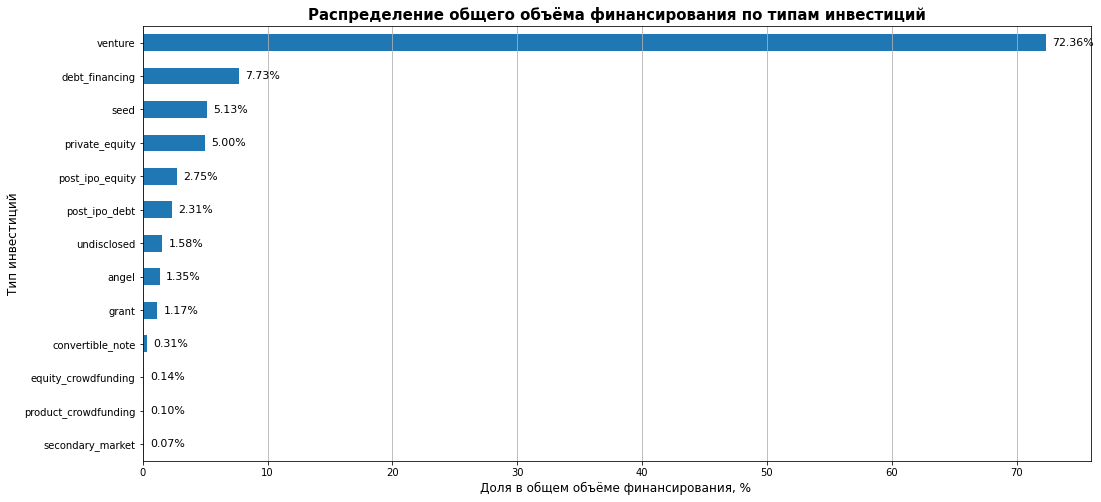

In [53]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(17, 8))

# Рассчитаем долю каждого типа инвестиций в общем объеме, выраженную в процентах (%).
a = (group_data * 1000000 / df_2[return_df.columns].sum().sum())*100

# Строим линейчатую диаграмму
ax = a.plot.barh()

# Настраиваем оформление графика
plt.title('Распределение общего объёма финансирования по типам инвестиций',fontsize=15, fontweight='bold')
plt.xlabel('Доля в общем объёме финансирования, % ', fontsize=12)
plt.ylabel('Тип инвестиций', fontsize=12)
plt.xticks(rotation=0)
for i, (index, value) in enumerate(a.items()):
     ax.text(value + 0.5, i, f'{value:.2f}%', va='center', fontsize=11)
plt.grid(axis='x')
plt.show()

Построим график, который покажет популярность разных типов финансирования — какие типы финансирования чаще всего используются компаниями.

In [54]:
# Рассчитаем количество компаний для каждого типа финансирования
group_data_2 = df_2[return_df.columns].apply(lambda x: (x > 0).sum()).sort_values(ascending=True)
group_data_2

secondary_market            8
post_ipo_debt              29
post_ipo_equity           177
product_crowdfunding      205
equity_crowdfunding       516
convertible_note          522
private_equity            680
undisclosed               834
grant                    1020
angel                    2938
debt_financing           3312
seed                    13388
venture                 19060
dtype: int64

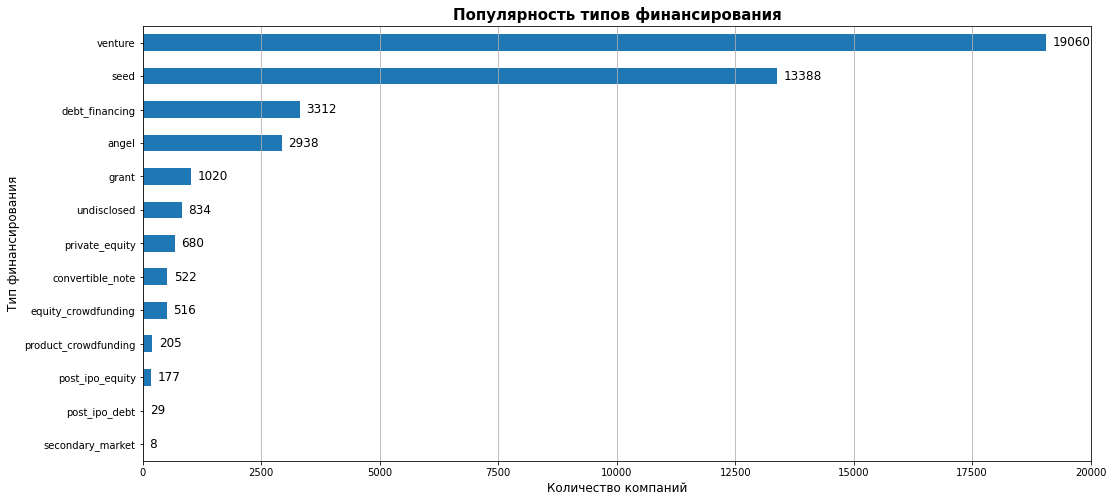

In [55]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(17, 8))

# Строим линейчатую диаграмму
ax = group_data_2.plot.barh()

# Настраиваем оформление графика
plt.title('Популярность типов финансирования', fontsize=15, fontweight='bold')
plt.xlabel('Количество компаний', fontsize=12)
plt.ylabel('Тип финансирования', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='x')
for i, (index, value) in enumerate(group_data_2.items()):
    ax.text(value + group_data.max() * 0.001, i, f'{value}', 
            va='center',fontsize=12)

plt.show()

Сравним полученные результаты и выделим часто используемые типы финансирования, которые при этом характеризуются небольшими объёмами, и наоборот — те, что встречаются редко, но при этом характеризуются значительным объёмом предоставленных сумм.
Для наглядности объединим таблицы в один датафрейм и посчитаем средний чек финансирования в млн долл.

In [56]:
# Объединяем в один DataFrame
summary_table = pd.DataFrame({
    'Количество компаний': group_data_2,
    'Суммарный объём, млн $': group_data
}).sort_values('Количество компаний', ascending=False)
# Создадим колонку средний чек
summary_table['Средний чек, млн $'] = summary_table['Суммарный объём, млн $'] / summary_table['Количество компаний']
summary_table

,Количество компаний,"Суммарный объём, млн $","Средний чек, млн $"
venture,19060,133987.221504,7.029760
seed,13388,9494.127616,0.709152
debt_financing,3312,14305.183744,4.319198
angel,2938,2501.263872,0.851349
grant,1020,2168.262400,2.125747
undisclosed,834,2924.353024,3.506418
private_equity,680,9262.412800,13.621195
convertible_note,522,567.144896,1.086484
equity_crowdfunding,516,262.960656,0.509614
product_crowdfunding,205,193.310272,0.942977


Самый популярный тип инвестиций — это венчурное финансирование (venture). Его используют 19 тысяч компаний, и средняя сумма сделки — около 7 млн долларов. Это основной двигатель рынка.

Посевные инвестиции (seed) тоже очень популярны (более 13 тысяч компаний), но там суммы скромнее — в среднем 0.7 млн долларов. Это самый массовый входной инструмент для стартапов.

Есть и редкие, но крупные типы. Например, Post-IPO debt используется всего 29 компаниями, но средняя сумма достигает почти 148 млн долларов. Такие инструменты нужны уже зрелым компаниям, а не новичкам.

Краудфандинг и Convertible Note — занимают нишу малых сумм и невысокой популярности. Они подходят для маленьких проектов или альтернативных способов привлечения денег.

Итог: рынок делится на массовые инструменты для стартапов (seed, venture) и редкие, но крупные — для взрослых компаний. Основные деньги идут через venture, а инвестиций на посевной стадии — это самый частый первый шаг.

Построим график суммарных объёмов возвратов от разных типов финансирования за весь период на основе датасета `return_df`.

In [57]:
# Рассчитаем сумму возвращенных средств для каждого типа финансирования в млн. долл.
group_data_3 = return_df.sum().sort_values(ascending = True)
group_data_3

grant                       0.00
product_crowdfunding        1.86
equity_crowdfunding         3.83
secondary_market            5.20
convertible_note           34.79
post_ipo_debt              91.03
undisclosed               730.88
post_ipo_equity          1104.96
angel                    1509.23
seed                     2382.24
private_equity           3587.33
debt_financing           4734.85
venture                 40578.62
dtype: float64

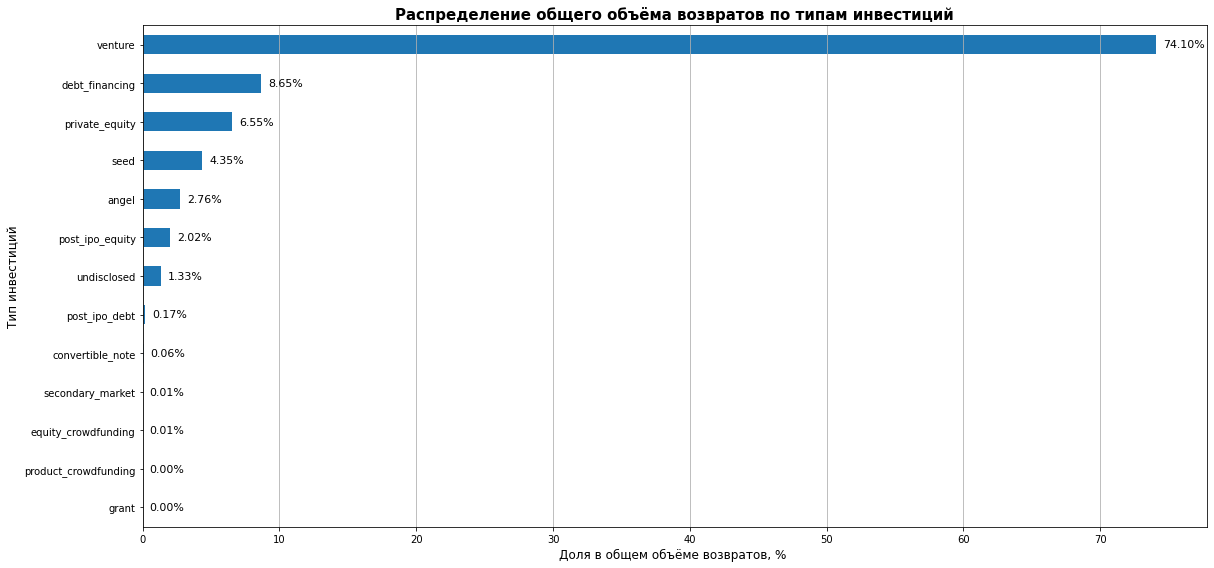

In [58]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(17, 8))

# Рассчитаем долю каждого типа возвратов в общем объеме, выраженную в процентах (%).
b = group_data_3 / return_df.sum().sum()*100

# Строим линейчатую диаграмму
ax = b.plot.barh()


# Настраиваем оформление графика
plt.title('Распределение общего объёма возвратов по типам инвестиций',fontsize=15, fontweight= 'bold')
plt.xlabel('Доля в общем объёме возвратов, % ', fontsize=12)
plt.ylabel('Тип инвестиций', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='x')
for i, (index, value) in enumerate(b.items()):
     ax.text(value + 0.5, i, f'{value:.2f}%', va='center', fontsize=11)
plt.tight_layout()
plt.show()

Выведем оба графика вместе

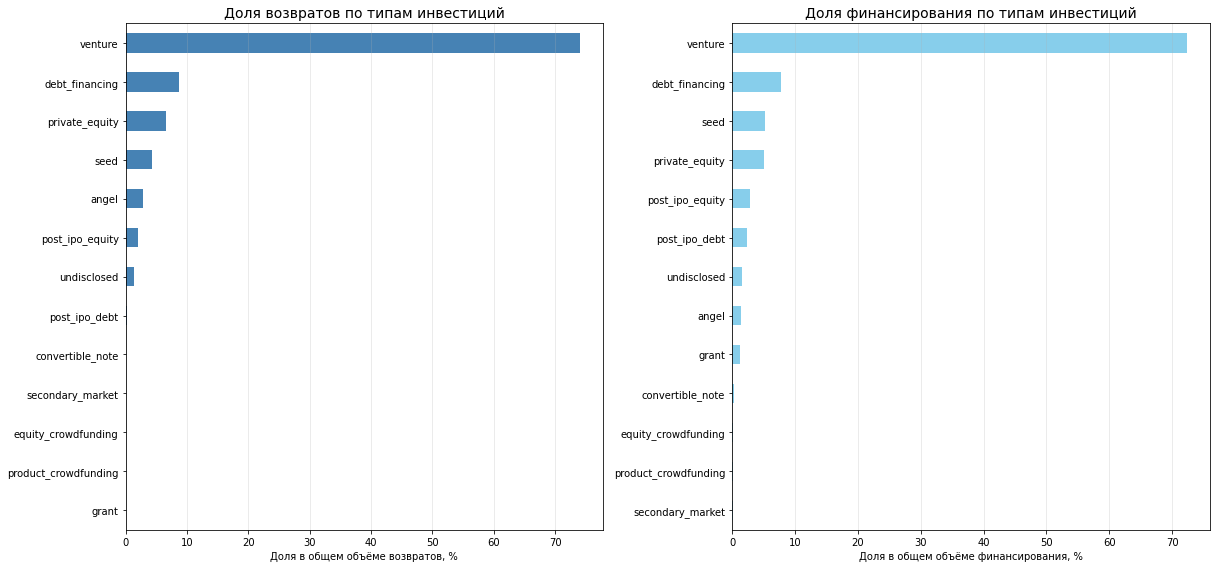

In [59]:
 fig, axes = plt.subplots(1, 2, figsize=(17, 8))

# График 1: Возвраты
b.sort_values().plot.barh(ax=axes[0], color='steelblue')
axes[0].set_title('Доля возвратов по типам инвестиций', fontsize=14)
axes[0].set_xlabel('Доля в общем объёме возвратов, %')
axes[0].grid(axis='x', alpha=0.3)

# График 2: Финансирование
a.sort_values().plot.barh(ax=axes[1], color = 'skyblue')
axes[1].set_title('Доля финансирования по типам инвестиций', fontsize=14)
axes[1].set_xlabel('Доля в общем объёме финансирования, %')
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

Абсолютный лидер по объёму возвратов — `венчурное финансирование (venture)` — 74%. Это почти в 10 раз больше, чем у ближайшего финансирования (debt_financing — 8,6 %). `Venture` является самым популярным типом инвестиций и именно он генерирует основной возврат денежных средств инвесторов. 

В Топ-3 типов по объёму возвратов входят: `венчурное финансирование (venture)` - 40578 млн долл, `долговое финансирование (debt_financing)` - 4734 млн долл и  `прямые инвестиции или частный капитал (private_equity)` - 3587 млн долл. 

Остальные типы инвестиций обеспечивают значительно меньшие объёмы возвратов. `Angel` (1509 млн долл), `seed` (2382 млн долл.) и `post_ipo_equity` (1104 млн долл) — это категории, которые либо работают с небольшими суммами (инвестиций от бизнес-ангелов и посевные инвестиции), либо редко встречаются на рынке (долговое финансирования после IPO). Наименьшие показатели возвратов зафиксированы у `grant` (0 млн), `product_crowdfunding` (1.86 млн долл) и `equity_crowdfunding` (3.83 млн долл), что подтверждает их нишевый характер.

Таким образом, рынок возвратов полностью коррелирует с рынком объёмов финансирования: самые популярные и крупные типы инвестиций приносят и самые большие возвраты.

`Venture` — абсолютный лидер как по числу компаний, так и по объёму возвратов.

`Seed` — широко распространён, но возвраты скромны (2382 млн долл), так как суммы инвестиций на этом этапе невелики.

`Debt_financing` — уступает по популярности (3 312 компаний), но демонстрирует высокую эффективность возвратов (4734 млн долл), что подтверждает надёжность долговых инструментов.

`Grant` —  не генерирует возвратов (0 млн долл), так как гранты предоставляются на безвозмездной основе.


##  Анализ динамики

### Динамика предоставления финансирования по годам
Рассчитаем для каждой компании средний объём одного раунда финансирования и построим график, отражающий динамику типичного размера средств, которые стартапы получали в рамках одного раунда финансирования.

In [60]:
# Рассчитаем для каждой компании средний объёмо дного раунда финансирования
df_2['funding_per_round'] = df_2['funding_total_usd'] / df_2['funding_rounds']

In [61]:
# Найдем медианное значение одного раунда финансирования по годам
group_data_3 = df_2.groupby(df_2['mid_funding_at'].dt.year)['funding_per_round'].median()/1000000
group_data_3

mid_funding_at
2000    2.365234
2001    2.368582
2002        3.75
2003       1.505
2004    3.066667
2005         4.5
2006    3.945338
2007    2.893271
2008       2.225
2009         1.5
2010        1.29
2011    0.876963
2012         0.7
2013       0.575
2014         0.6
Name: funding_per_round, dtype: Float64

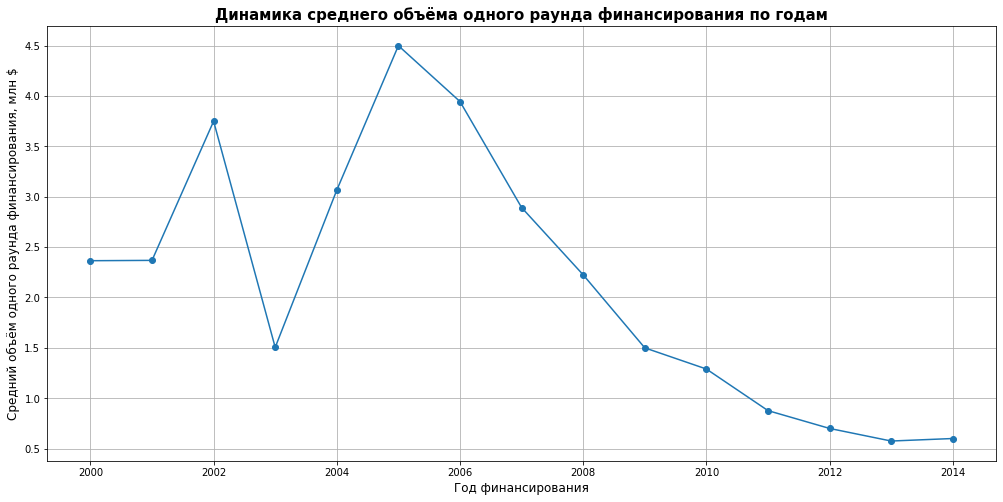

In [62]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(17, 8))

# Строим линейный график
ax = group_data_3.plot.line(marker='o')

# Настраиваем оформление графика
plt.title('Динамика среднего объёма одного раунда финансирования по годам', fontsize=15, fontweight='bold')
plt.xlabel('Год финансирования', fontsize=12)
plt.ylabel('Средний объём одного раунда финансирования, млн $', fontsize=12)
plt.xticks(rotation=0)
plt.grid()

plt.show()


Построим график, отражающий динамику общего количества раундов за каждый год, то есть насколько активно происходили инвестиции на рынке (чем больше раундов, тем выше активность).

In [63]:
# Найдем суммарное количество раундов по годам
group_data_4 = df_2.groupby(df_2['mid_funding_at'].dt.year)['funding_rounds'].sum()
group_data_4

mid_funding_at
2000      122
2001       84
2002      107
2003      128
2004      189
2005      958
2006     1881
2007     2849
2008     3686
2009     4669
2010     6199
2011     7617
2012     9753
2013    12945
2014     7244
Name: funding_rounds, dtype: Int64

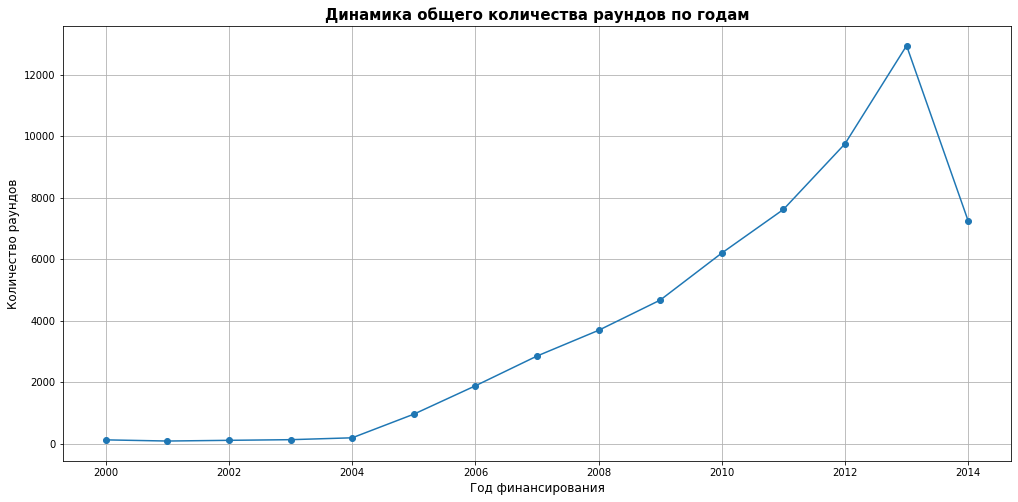

In [64]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(17, 8))

# Строим линейный график
ax = group_data_4.plot.line(marker='o')

# Настраиваем оформление графика
plt.title('Динамика общего количества раундов по годам', fontsize=15, fontweight='bold')
plt.xlabel('Год финансирования', fontsize=12)
plt.ylabel('Количество раундов', fontsize=12)
plt.xticks(rotation=0)
plt.grid()

plt.show()

Максимальный типичный размер раунда (по медиане) был зафиксирован в 2005 году и составил 4,5 млн долл.
В период с 2004 по 2006 год медианный чек раунда находился на высоком уровне — от 3 до 4,5 млн долл, после чего начал устойчиво снижаться. Это может говорить о том, что рынок стал более "посевным" — появилось много маленьких стартапов, которым требовались небольшие суммы на старте.
В 2014 году наблюдались следующие тенденции:
количество раундов резко сократилось — до 7244 (почти в два раза меньше, чем в 2013 году — 12945);
средний размер раунда остался практически на уровне 2013 года (0,6 млн долл. против 0,575 млн долл) — отмечен лишь незначительный рост.
2014 год стал переломным — рынок сократил количество сделок, но сохранил средний чек. Вероятно, инвесторы стали более избирательными и предпочитали вкладываться в меньшее количество проектов, но с чуть большими суммами.

###  Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов

Составим сводную таблицу, в которой указывается суммарный размер общего финансирования `funding_total_usd` по годам и сегментам рынка. Отберем только те сегменты, которые показывали рост размера суммарного финансирования в 2014 году по сравнению с 2013.

In [65]:
# Отфильтруем датафрейм по массовым сегментам рынка и оставим только заполненные значения
df_filtered = df_2[~df_2['market'].isin(['niche', 'mid']) & df_2['market'].notna()]
df_filtered

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,round_B,round_C,round_D,round_E,round_F,round_G,round_H,funding_type,anomaly,funding_per_round
3,University of Michigan,http://www.umich.edu/,|Education|,education,7700000,operating,USA,MI,Detroit,Ann Arbor,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,менее года,False,2566666.666667
4,Case Western Reserve University,http://www.case.edu,|Education|,education,540000,operating,USA,OH,Cleveland,Cleveland,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,единичное,False,540000.0
7,Duke University,http://www.duke.edu,|Education|,education,8700000,operating,USA,NC,Raleigh,Durham,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,единичное,False,8700000.0
9,WeGame,http://www.WeGame.com,|Social Media|,social media,3500000,acquired,USA,CA,SF Bay Area,San Francisco,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,менее года,False,1750000.0
11,Mayne Pharma,http://www.maynepharma.com,|Biotechnology|,biotechnology,2705000,operating,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,единичное,False,2705000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49417,Dashboard Systems,http://www.boardmaps.com,|Project Management|Software|,software,2190000,operating,RUS,NaN,Moscow,Moscow,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,единичное,False,2190000.0
49423,IzumoBase,http://izumobase.com/en/,|Software|,software,1350000,operating,JPN,NaN,Tokyo,Tokyo,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,единичное,False,1350000.0
49424,LoudCell Technologies,http://loudcell.com/,|Software|,software,1000000,operating,USA,CA,SF Bay Area,Santa Clara,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,единичное,False,1000000.0
49427,A Crowd of Monsters,http://acrowdofmonsters.com,|Games|,games,560248,operating,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,единичное,False,560248.0


In [66]:
# Составим сводную таблицу, в которой указывается суммарный размер общего финансирования по годам и сегментам рынка в млн $.
pivot_funding = pd.pivot_table(df_filtered,
                             index= df_filtered['mid_funding_at'].dt.year,
                             columns= 'market',
                             values= 'funding_total_usd',
                             aggfunc='sum', 
                            fill_value=0) / 1000000  
pivot_funding

market,advertising,analytics,apps,automotive,big data,biotechnology,clean technology,cloud computing,consulting,curated web,...,semiconductors,social media,social network media,software,sports,startups,technology,travel,video,web hosting
mid_funding_at,,,,,,,,,,,,,,,,,,,,,
2000,14.47,14.822803,0.0,0.0,0.0,0.0,0.0,11.5,4.5,1.0,...,0.0,0.0,0.0,31.73264,0.0,0.0,0.0,0.05023,0.0,95.34309
2001,8.778321,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.305,...,101.727992,0.65,0.0,27.811352,0.0,0.0,22.16,0.0,0.0,15.0
2002,24.5,7.5,0.0,0.0,0.0,0.0,34.390435,0.0,0.0,4.65,...,0.0,0.0,0.0,101.026395,0.2,0.0,11.0,0.0,0.0,0.0
2003,10.5,3.84,0.0,4.53,0.0,85.531178,50.352939,0.0,0.0,2.55,...,28.0,0.005,0.0,66.086037,0.0,0.0,0.0,0.0,5.0,0.0
2004,6.0,3.0,0.0,0.0,0.0,97.184859,50.427954,0.0,0.0,27.05,...,88.782797,6.85,0.0,140.823795,0.0,0.0,1.75,10.23,14.704,27.0
2005,127.196022,79.014044,0.0,22.5,0.0,480.063583,19.42,0.0,44.862,53.45,...,586.220751,14.78,5.2,993.076581,1.8822,0.0,50.728425,27.83,6.470551,483.332632
2006,299.299458,139.701311,1.3106,12.66,0.0,903.500543,131.473889,9.951809,23.965548,164.673698,...,1227.940797,60.16988,5.2451,1646.868624,7.0,0.0,22.791,11.7,35.171772,649.959267
2007,556.704331,98.829,0.0,37.712601,7.78,1704.078338,749.711239,20.354343,70.346345,314.704515,...,1616.604148,89.022516,24.104021,1686.115571,16.40158,0.0,180.190209,13.95,85.150644,361.121449
2008,622.673464,208.07784,4.3,59.478635,2.452515,1716.033,3165.808492,44.375,19.06108,336.500027,...,1107.199296,76.034534,10.998076,1365.005648,9.55479,5.010387,277.726238,54.905631,37.865177,781.623731


In [67]:
# Отберем только те сегменты, которые показывали рост размера суммарного финансирования в 2014 году по сравнению с 2013.
final_pivot_funding = pivot_funding.loc[:, pivot_funding.loc[2014] > pivot_funding.loc[2013]]
final_pivot_funding

market,apps,big data,design,internet,manufacturing,medical,real estate,saas,startups,technology
mid_funding_at,,,,,,,,,,
2000,0.0,0.0,0.0,10.0,56.65931,24.0,2.5,0.0,0.0,0.0
2001,0.0,0.0,0.0,0.0,2.368582,0.0,0.0,0.0,0.0,22.16
2002,0.0,0.0,0.0,1.1,0.0,0.0,5.275,2.0,0.0,11.0
2003,0.0,0.0,0.0,0.0,4.269608,0.0,6.2922,0.0,0.0,0.0
2004,0.0,0.0,0.0,10.5,3.0,0.0,0.0,0.0,0.0,1.75
2005,0.0,0.0,9.3,1.775,61.77,11.09,0.25,5.24,0.0,50.728425
2006,1.3106,0.0,0.707,0.005,163.957751,20.25,2.08,4.791121,0.0,22.791
2007,0.0,7.78,10.8,4.495379,147.726051,2.1,33.22,14.652595,0.0,180.190209
2008,4.3,2.452515,5.944302,23.412964,173.05426,28.812744,46.6131,27.2269,5.010387,277.726238


Построим график, отражающий, как менялся суммарный размер общего финансирования в каждом из отобранных сегментов по годам.

<Figure size 720x504 with 0 Axes>

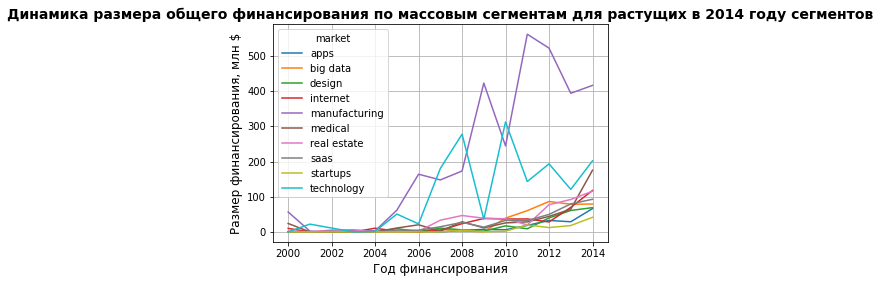

In [68]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(10, 7))

# Строим линейный график
ax = final_pivot_funding.plot.line()

# Настраиваем оформление графика
plt.title(
    'Динамика размера общего финансирования по массовым сегментам '
    'для растущих в 2014 году сегментов',
    fontsize=14,
    fontweight='bold'
)
plt.xlabel('Год финансирования', fontsize=12)
plt.ylabel('Размер финансирования, млн $', fontsize=12)
plt.xticks(rotation=0)
plt.grid()

plt.show()

Вывод На основе графика сделайте вывод о том, какие сегменты показывают наиболее быстрый и уверенный рост.

Абсолютный лидер по объёму финансирования — `manufacturing` (более 416 млн $ в 2014 году), который также показывает стабильный рост.

Наиболее перспективными для инвестиций с точки зрения динамики можно считать:

`apps` — самый высокий темп роста. В 2006 году — 1.31 млн долл, 2014 году — 66.24 млн долл. Примерно в 50 раз.

`medical`: плавный, уверенный рост без спадов. В 2000 году — 24 млн долл, к 2014 году — 175.24 млн долл. Рост почти в 7,3 раз.

`real estate`: устойчивый, ускорение роста после 2011 года. В 2000 году — 2.5 млн долл, к 2014 году — 115.57 млн долл. Рост примерно в 46 раз.

Стабильно растущие сегменты с большим масштабом:

`saas` - в 2005 году — 5.24 млн долл, к 2014 году — 92.81 млн долл. Рост почти в 18 раз. 

`internet` - в 2000 году — 10 млн долл, к 2014 году — 117.83 млн долл. Рост в 11.8 раз. 

### Годовая динамика доли возвращённых средств по типам финансирования

Для каждого года и каждого вида финансирования рассчитаем нормированные значения возврата средств.

In [69]:
# Выведем список типов инвестирования из датафрейма return_df
columns_to_sum = return_df.columns.tolist()

# Рассчитаем сумму привлеченных средств для каждого типа финансирования по годам (в млн. долл.)
df_invest_year = df_2.groupby(df_2.mid_funding_at.dt.year)[columns_to_sum].sum()/1000000
df_invest_year

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
mid_funding_at,,,,,,,,,,,,,
2000,16.759140,375.362144,0.000000,215.502640,0.000000,14.000000,24.086332,0.293114,0.000000,3.467747,0.000000,7.718867,0.000000
2001,26.398964,285.220672,0.000000,46.524068,1.500000,5.829217,1.000000,0.100000,0.000000,0.000000,0.000000,0.000000,0.000000
2002,10.465192,342.362912,0.000000,42.323732,0.000000,15.309671,3.000000,0.000000,46.441876,0.300000,0.000000,0.000000,0.000000
2003,15.318355,400.234432,0.000000,10.280000,0.000000,1.050000,5.629661,16.850716,0.000000,0.000000,0.000000,0.000000,0.000000
2004,18.104728,723.016192,0.000000,98.758160,0.000000,30.816624,11.013741,14.027534,0.000000,0.000000,0.000000,0.000000,0.000000
2005,39.425200,4902.948352,0.000000,8.871332,0.000000,101.720656,60.914620,6.266481,5.000000,4.796022,0.000000,0.000000,0.000000
2006,66.794776,9200.693248,0.933057,71.842904,11.807857,140.848400,70.756152,6.147500,35.820244,0.000000,0.000000,0.000000,0.000000
2007,192.296480,12151.590912,0.000000,109.649904,14.116788,657.901632,201.152448,34.237780,195.847872,12.000000,0.000000,0.000000,0.000000
2008,302.003008,14485.117952,0.000000,143.785520,28.600902,428.622048,249.299616,23.485348,191.756336,36.000000,0.000000,0.000000,1.000000


In [70]:
# Для каждого года и каждого вида финансирования рассчитаем нормированные значения возврата средств.
result = return_df / (df_invest_year+1e-60)
result

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2000,0.996471,0.147591,0.000000e+00,0.362919,0.000000e+00,0.618571,0.266956,0.0,0.000000e+00,2.710694e-01,0.000000,2.591054e-02,0.000000
2001,0.109095,0.082357,0.000000e+00,0.462126,6.666667e-03,0.770258,1.180000,0.0,0.000000e+00,4.600000e+59,0.000000,4.600000e+59,0.000000
2002,0.629707,0.611690,0.000000e+00,0.608878,2.000000e+58,0.223388,1.136667,0.0,3.251376e-02,1.133333e+00,0.000000,6.000000e+58,0.000000
2003,0.505276,0.584308,0.000000e+00,0.914397,1.000000e+58,1.038095,0.605720,0.0,1.620000e+60,2.110000e+60,0.000000,8.000000e+58,0.000000
2004,0.548476,0.768862,0.000000e+00,0.336073,1.000000e+58,0.439698,0.833504,0.0,2.190000e+60,3.380000e+60,0.000000,5.500000e+59,0.000000
2005,0.674695,0.536192,0.000000e+00,1.071992,2.000000e+58,0.344964,0.509894,0.0,4.800000e-01,7.318565e-01,0.000000,5.000000e+58,0.000000
2006,0.925372,0.336951,2.036317e-01,0.650586,1.507471e-01,0.803772,0.674853,0.0,4.653793e-01,2.058000e+61,0.000000,1.200000e+59,0.000000
2007,0.366153,0.295054,1.000000e+58,0.504971,2.280972e-01,0.191032,0.817837,0.0,4.534642e-01,2.030000e+00,0.000000,5.700000e+59,0.000000
2008,0.297083,0.187573,3.000000e+58,0.285286,5.978832e-02,0.927484,0.412476,0.0,6.799254e-01,2.341111e+00,0.000000,4.700000e+59,0.000000


Заменим слишком большие аномальные значения на пропуски.

In [71]:
# Убираем явные выбросы
df_result = result.copy()
df_result = df_result.where(df_result <= 1e+15, float('nan'))


In [72]:
df_result

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2000,0.996471,0.147591,0.000000,0.362919,0.000000,0.618571,0.266956,0.0,0.000000,0.271069,0.000000,0.025911,0.000000
2001,0.109095,0.082357,0.000000,0.462126,0.006667,0.770258,1.180000,0.0,0.000000,NaN,0.000000,NaN,0.000000
2002,0.629707,0.611690,0.000000,0.608878,NaN,0.223388,1.136667,0.0,0.032514,1.133333,0.000000,NaN,0.000000
2003,0.505276,0.584308,0.000000,0.914397,NaN,1.038095,0.605720,0.0,NaN,NaN,0.000000,NaN,0.000000
2004,0.548476,0.768862,0.000000,0.336073,NaN,0.439698,0.833504,0.0,NaN,NaN,0.000000,NaN,0.000000
2005,0.674695,0.536192,0.000000,1.071992,NaN,0.344964,0.509894,0.0,0.480000,0.731857,0.000000,NaN,0.000000
2006,0.925372,0.336951,0.203632,0.650586,0.150747,0.803772,0.674853,0.0,0.465379,NaN,0.000000,NaN,0.000000
2007,0.366153,0.295054,NaN,0.504971,0.228097,0.191032,0.817837,0.0,0.453464,2.030000,0.000000,NaN,0.000000
2008,0.297083,0.187573,NaN,0.285286,0.059788,0.927484,0.412476,0.0,0.679925,2.341111,0.000000,NaN,0.000000


Построим график, на котором отобразим нормированные значения возврата средств для типов финансирования venture, debt_financing, private_equity, seed и angel.

<Figure size 1080x504 with 0 Axes>

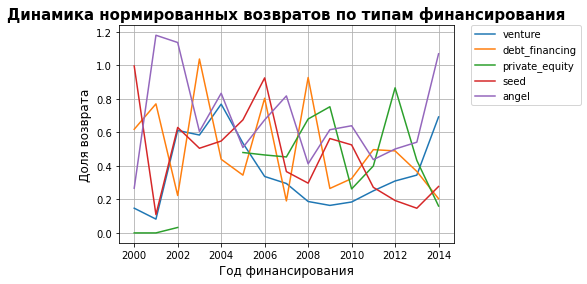

In [73]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(15, 7))

# Строим линейчатую диаграмму
ax = df_result[['venture', 'debt_financing', 'private_equity', 'seed', 'angel']].plot.line()

# Настраиваем оформление графика
plt.title('Динамика нормированных возвратов по типам финансирования', fontsize=15, fontweight='bold')
plt.xlabel('Год финансирования', fontsize=12)
plt.ylabel('Доля возврата', fontsize=12)
plt.xticks(rotation=0)
plt.grid()
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0)

plt.show()

Среди пяти анализируемых типов финансирования наиболее устойчивый и уверенный рост нормированного показателя возвратов демонстрирует венчурное финансирование (`venture`): с 0.15 в 2000 году до 0.69 в 2014 году. Венчурные инвестиции растут постепенно и без резких обвалов. Это значит, что они становятся всё более выгодными и надёжными.

Посевные инвестиции (`seed`) показывают признаки восстановления после длительного спада: в 2014 году показатель вырос до 0.277 против 0.147 годом ранее.

Долговое финансирование (`debt_financing`) и частные инвестиции (`private_equity`) не имеют устойчивого тренда и сильно колеблются от года к году.

Ангельские инвестиции (`angel`) продемонстрировали резкий всплеск до 1.07 в 2014 году, однако это единичный случай, который нельзя считать устойчивым трендом.


##  Итоговый вывод и рекомендации

В ходе проекта мы исследовали динамику и структуру финансирования стартапов на основе двух датасетов: cb_investments (информация о компаниях и состоявшемся финансировании) и cb_returns ( информация об объёмах возвратов по годам и типам финансирования ). 

На этапе очистки мы привели данные к единым типам, заполнили пропуски в значениях mid_funding_at, были удалены строки, которые не содержат данных о финансировании и не несут какой-либо информации . 

Компании были разделили по длительности привлечения капитала (единичное финансирование, срок финансирования до года, срок финансирования более года.), а рыночные сегменты распределили по трём категориям: массовые, средние и нишевые. В ходе дальнейшего анализа средние и нишевые группы были объединены в обобщённые категории ('mid' и 'niche' соответственно), а с помощью межквартильного размаха (IQR) мы очистили данные от аномально крупных сделок.

На основе анализа рынка инвестиций можно выделить несколько ключевых тенденций:

Структура финансирования стартапов:
- 59% компаний получили единичное финансирование
- 30% — долгосрочные проекты (> года)
- 11% — финансирование в течение года
- 62% объёма инвестиций приходится на долгосрочные проекты.  Это позволяет предположить, что долгосрочные инвестиционные отношения сопряжены с более значительными вложениями.

Распределение по сегментам:

- 73.4% сегментов — нишевые (< 35 компаний)
- 14.5% — средние (35–120 компаний)
- 12.2% — массовые (> 120 компаний)

По типам финансирования:

- `Venture` — абсолютный лидер: 
    - 19 тыс. компаний; 
    - средняя сумма сделки — 7 млн долларов; 
    - обеспечивает 74 % всех возвратов; 
    - устойчивый рост нормированного показателя возвратов (с 0,15 в 2000 г. до 0,69 в 2014 г.).
- `Seed` —  массовый входной инструмент: 
    - более 13 тыс. компаний; 
    - средний чек — 0,7 млн долларов;
    - возвраты скромные (2382 млн долларов), но есть признаки восстановления после спада.
- `Debt_financing`: высокая эффективность возвратов (4734 млн долларов), но ниже популярность (3312 компаний).

Динамика рынка:

- Пик среднего размера раунда — 2005 год (4,5 млн долларов). После 2006 года размер чеков стал снижаться.
- В 2014 году рынок резко сократил число сделок (с 12 945 до 7244), но сохранил средний чек. Это говорит о том, что инвесторы стали более избирательными, предпочитая вкладываться в меньшее количество проектов, но с сохранением привычного уровня финансирования

В преддверии 2015 года лучше всего инвестировать в проекты в сферах `medical`, `apps` и `real estate` через механизм венчурного финансирования (`venture`). Эти сегменты показывают устойчивый рост, а venture-инвестиции — наиболее надёжный и эффективный инструмент с точки зрения возврата средств. В отличие от венчурных инвестиций, которые требуют крупных вложений на поздних стадиях, `Seed` даёт возможность зайти в проект дёшево и на раннем этапе. Это идеальный инструмент для диверсификации

Также стоит рассмотреть возможность инвестирования в средние сегменты рынка (35–120 компаний) — они уже прошли проверку рынком, но ещё не перенасыщены, в отличие от массовых сегментов.
